# New rails, old margins?

Does crypto remove the exchange-rate margin that makes up 54% of the cost of sending money from the UK, or move the cost somewhere else? This notebook rebuilds every number from `data/cache/` (offline) and tells the story in eight charts. Method and hypotheses: `PLAN.md`; caveats: `LIMITATIONS.md`.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from plumbing import report, plots
pd.set_option('display.max_colwidth', 120)
res = report.build(n_draws=1000)
figs = {p.stem: p for p in plots.make_all(res)}
res['windows']

,ramp_snapshots_from,ramp_snapshots_to,rounds,fee_window,requests_ok_share
0,2026-10-26 02:20:16.438868+00:00,2026-10-26 06:10:24.686602+00:00,24,2024-10-01..2026-09-30,1.0


## Hypotheses, written before the results
Five of six held. H4 did not: XRP's price risk exceeded its saving in only two corridors, and those savings came from local premiums.

In [2]:
res['hypotheses'][['id', 'claim', 'result', 'held']]

,id,claim,result,held
0,H1,Stablecoin conversion cost >= cheapest provider's FX margin (>= 3 of 4 corridors),3 of 4 corridors,True
1,H2,"Protocol fees tiny on XRPL/Solana, >= 0.5% on Tron when burned; charged >= 10x protocol","XRPL 0.0000%, Solana 0.0005%, Tron burned 1.19%; Kraken USDC-Solana fee = 763x protocol",True
2,H3,"On-chain finality: < 10 s XRPL & Solana, < 2 min Tron; end-to-end slower than RPW median","XRPL ~7.9 s (two ledgers), Solana 0.21 s, Tron 57 s; first-time UK buyer faces a 24 h FCA cooling-off vs RPW median ...",True
3,H4,XRP 99% 10-min VaR exceeds the XRP rail's saving vs B1 in most corridors,VaR 1.20%; larger than the saving in 2 of 4 corridors (savings exist only where a local premium pays the recipient),False
4,H5,Stablecoins within ±0.5% of $1 in > 99% of hours; worst USDC episode > 5%,"USDC 99.85%, USDT 99.82% of hours; worst USDC hourly close $0.863",True
5,H6,"Local premium (India, Kenya) exceeds the difference between rails and varies > 2 pp","premium India 6.3%, Kenya 3.6% vs rail differences 0.3 and 0.9 pp; time variation in premium_history",True


## 1. Where your £200 goes
The exchange-rate share shrinks on the newer rails; fees take its place. In India and Kenya a local USDT premium (green, left of zero) pays the recipient: policy, not technology.

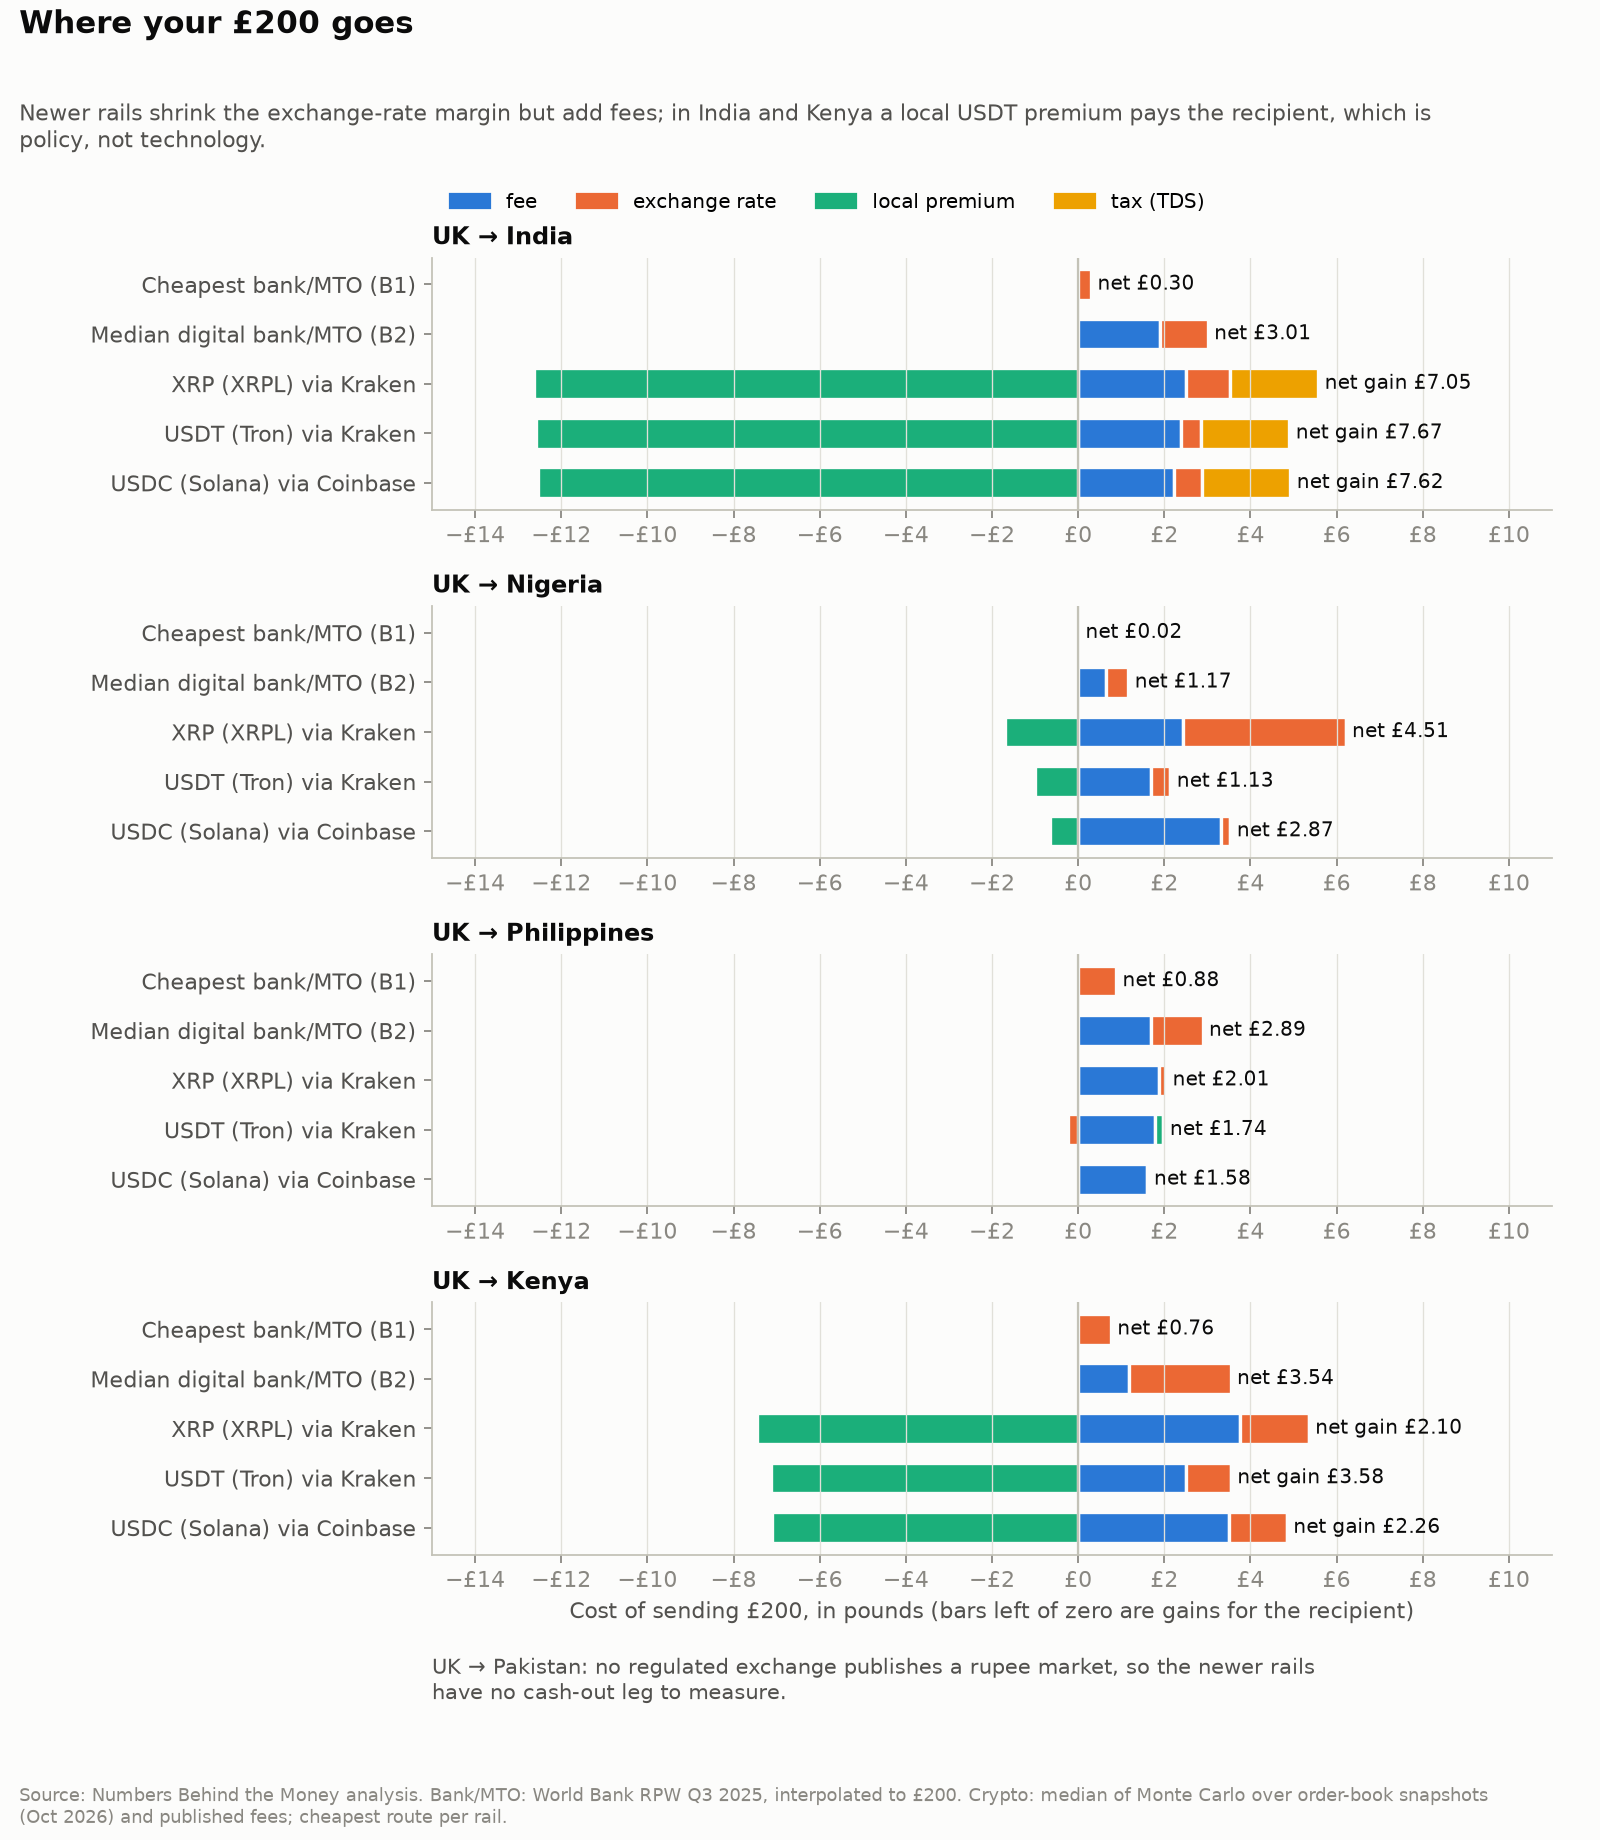

In [3]:
display(Image(figs['fig1_where_200_goes']))

## 2. Against the benchmarks, with uncertainty
Dots are medians excluding the local premium; lines are 5-95% ranges over order-book snapshots and published fee ranges.

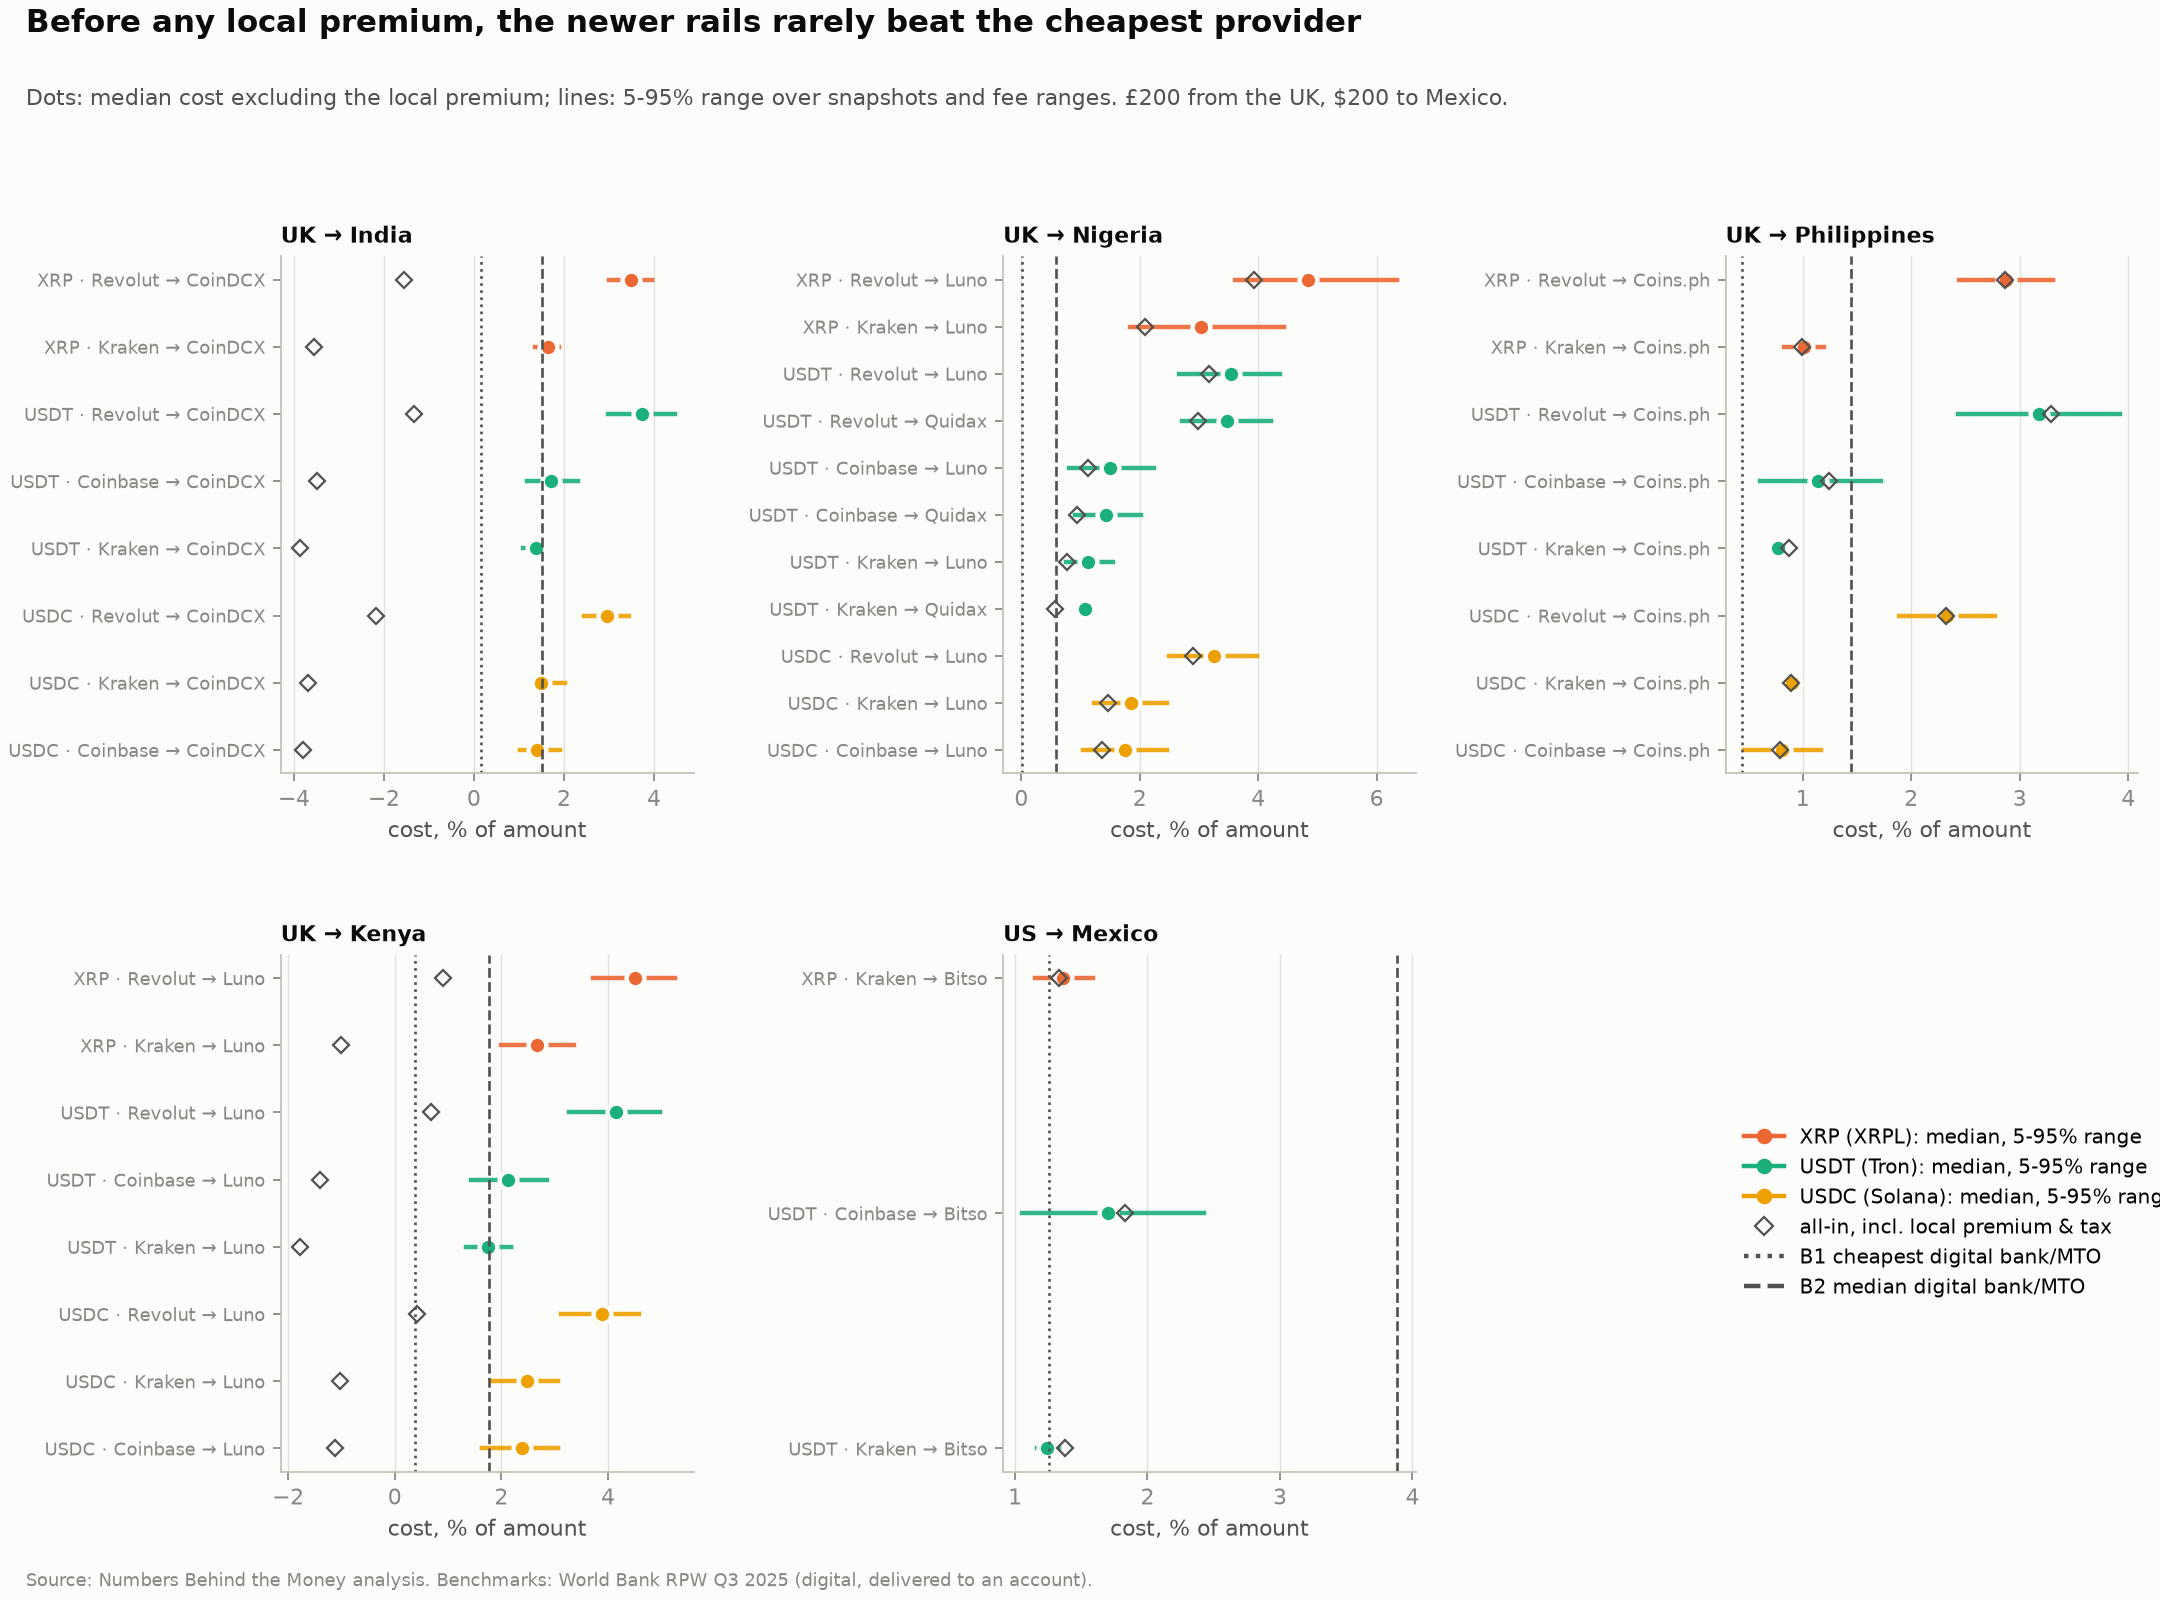

,corridor,asset,onramp,offramp,ex_premium_p05,ex_premium_p50,ex_premium_p95,B1,B2,P_beats_B1_ex_premium,P_beats_B2_ex_premium
0,GBR-IND,USDC,coinbase,coindcx,1.02,1.40,1.90,0.15,1.50,0.00,0.65
1,GBR-IND,USDT,kraken,coindcx,1.10,1.37,1.46,0.15,1.50,0.00,0.99
2,GBR-IND,XRP,kraken,coindcx,1.36,1.64,1.89,0.15,1.50,0.00,0.22
3,GBR-KEN,USDC,coinbase,luno_ke,1.64,2.38,3.06,0.38,1.77,0.00,0.09
4,GBR-KEN,USDT,kraken,luno_ke,1.34,1.74,2.19,0.38,1.77,0.00,0.52
5,GBR-KEN,XRP,kraken,luno_ke,1.99,2.67,3.37,0.38,1.77,0.00,0.01
6,GBR-NGA,USDC,coinbase,luno_ng,1.03,1.76,2.46,0.01,0.58,0.00,0.00
7,GBR-NGA,USDT,kraken,quidax,0.96,1.07,1.18,0.01,0.58,0.00,0.00
8,GBR-NGA,XRP,kraken,luno_ng,1.84,3.03,4.44,0.01,0.58,0.00,0.00
9,GBR-PHL,USDC,coinbase,coinsph,0.46,0.81,1.17,0.44,1.44,0.04,1.00


In [4]:
display(Image(figs['fig2_cost_vs_benchmarks']))
res['best'][['corridor','asset','onramp','offramp','ex_premium_p05','ex_premium_p50','ex_premium_p95','B1','B2','P_beats_B1_ex_premium','P_beats_B2_ex_premium']].round(2)

## 3. The local premium over time

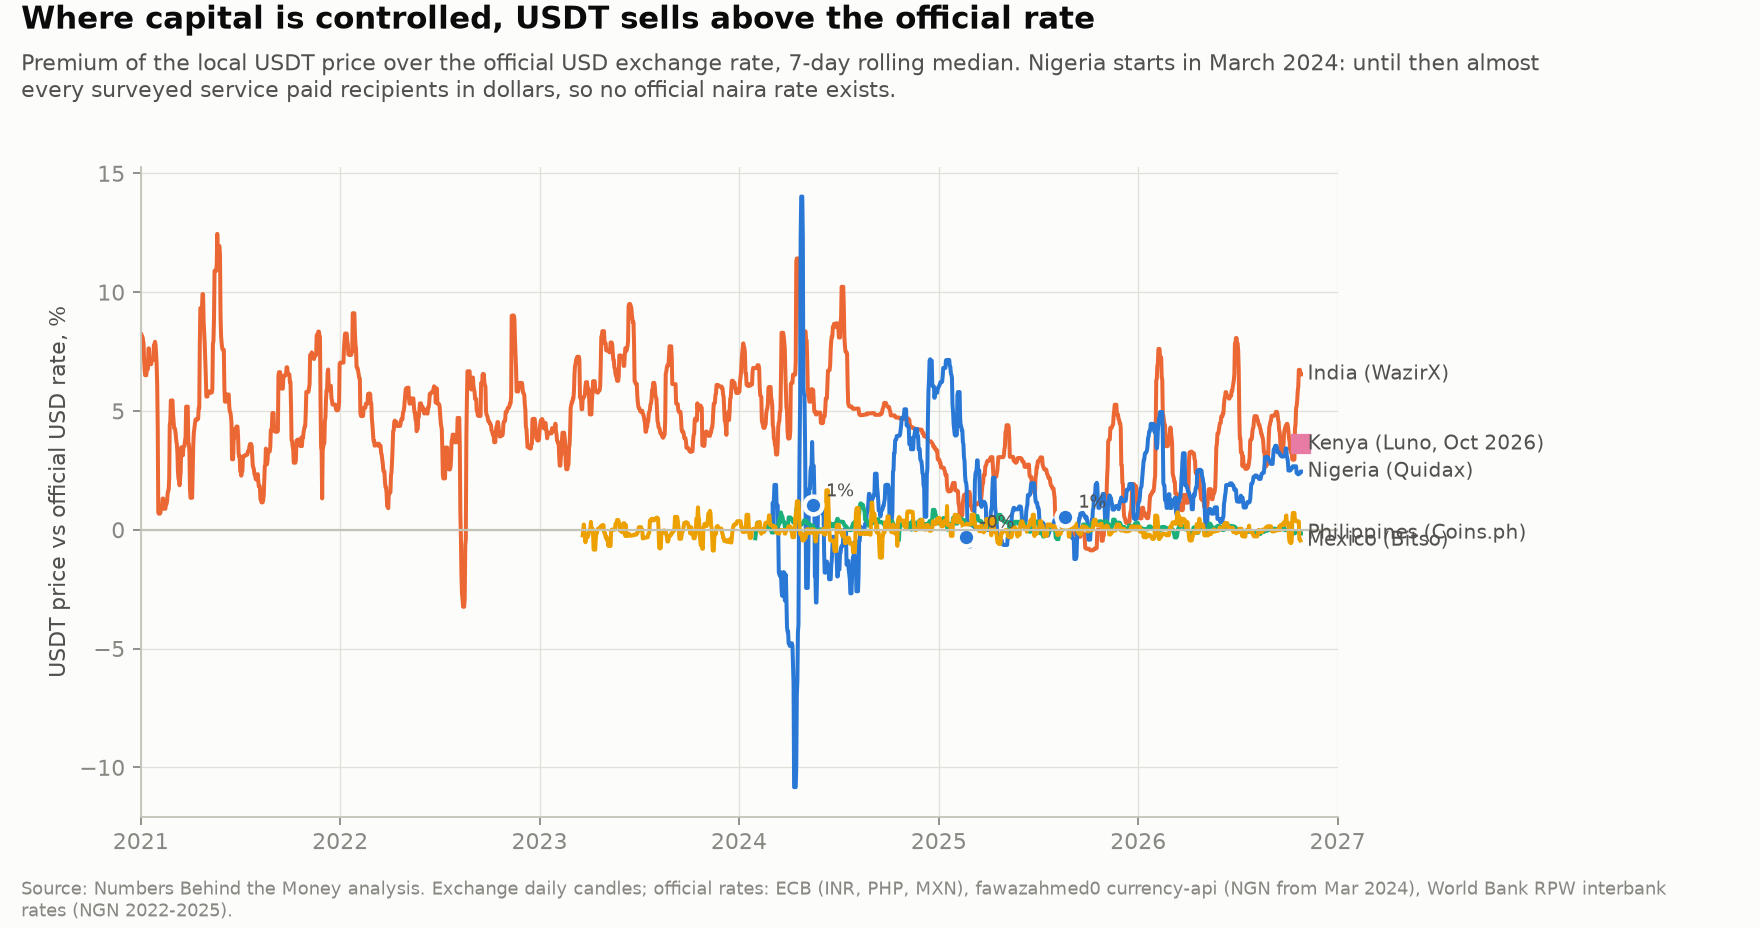

In [5]:
display(Image(figs['fig3_local_premium']))

## 4. Speed: on the ledger vs in the bank

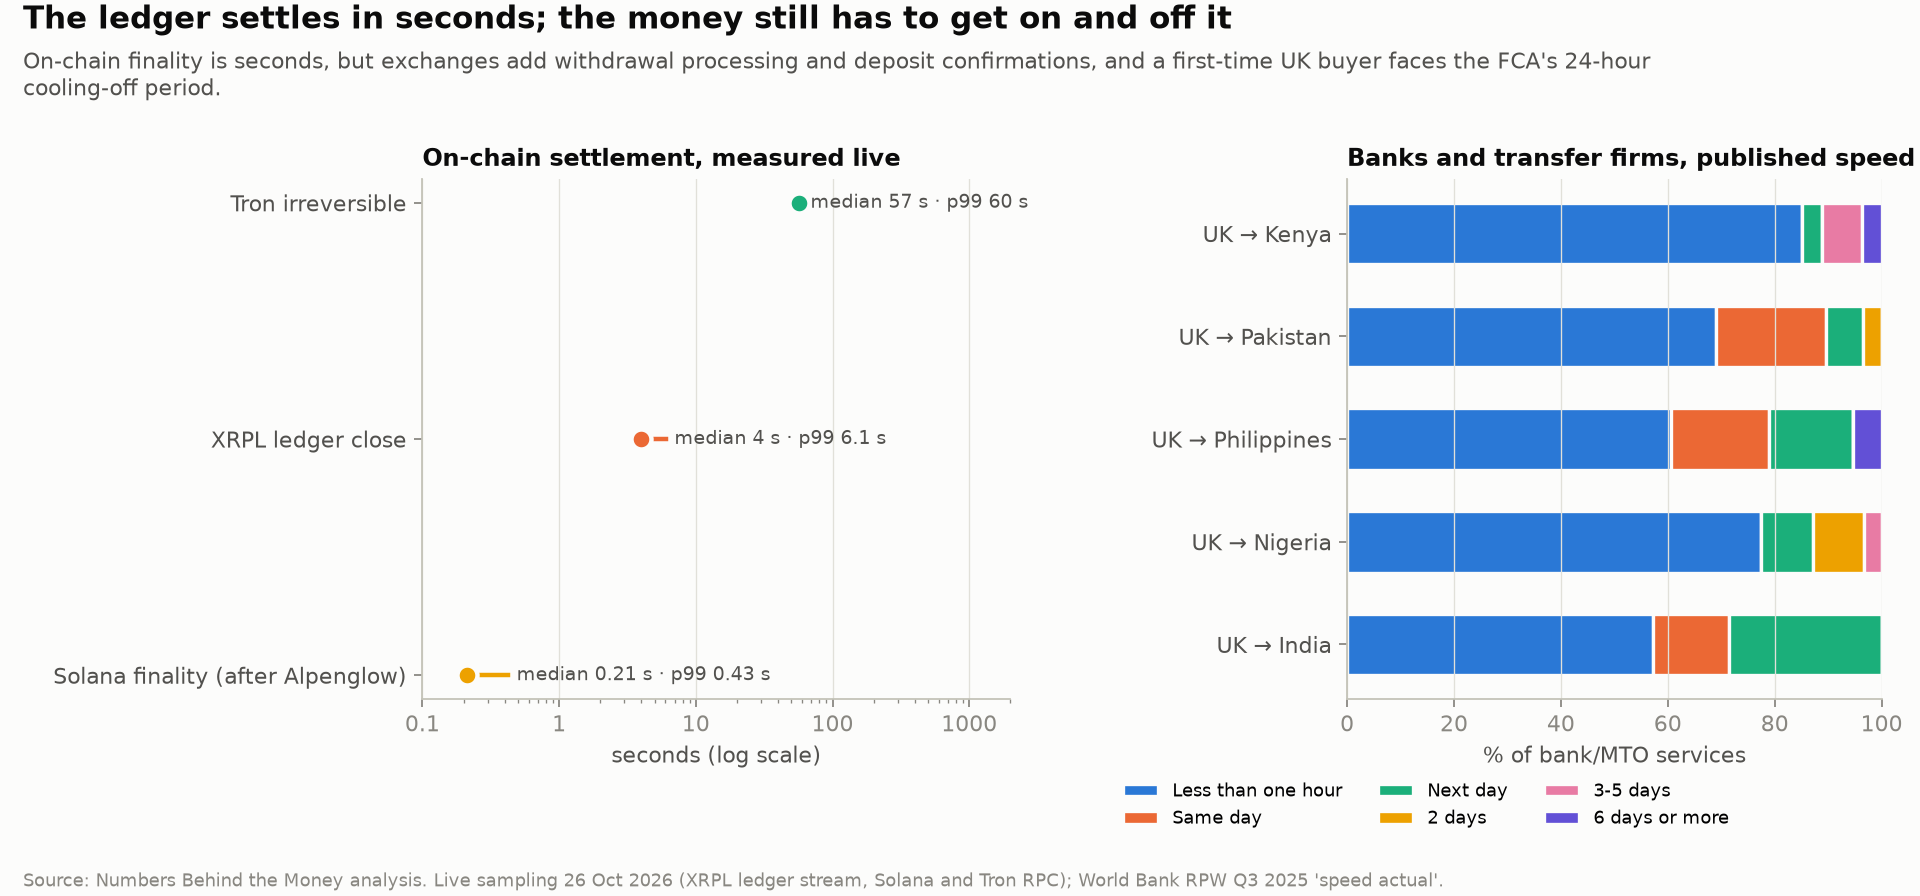

,measure,what,n,median_s,p95_s,p99_s,max_s
0,XRPL ledger interval (live stream),seconds between validated ledgers; a payment is final in its ledger,2727,3.971,5.047,6.068,12.058
1,XRPL mean interval per 100 ledgers (history),"Oct 2024-Sep 2026, stratified sample",504,3.900,3.910,3.990,4.000
2,"Solana finality lag (live, after Alpenglow)","processed -> finalized slot, x seconds per slot",3591,0.213,0.426,0.426,0.426
3,Solana slot time,node performance samples,3591,0.213,0.213,0.213,0.213
4,Tron block interval (live),seconds between consecutive blocks,1613,3.000,3.000,3.000,3.000
5,Tron solidification lag (live),head block -> irreversible (19 confirmations),2189,57.000,60.000,60.000,60.000


In [6]:
display(Image(figs['fig4_speed']))
res['speed']['onchain'].round(3)

## 5. XRP price risk during the transfer

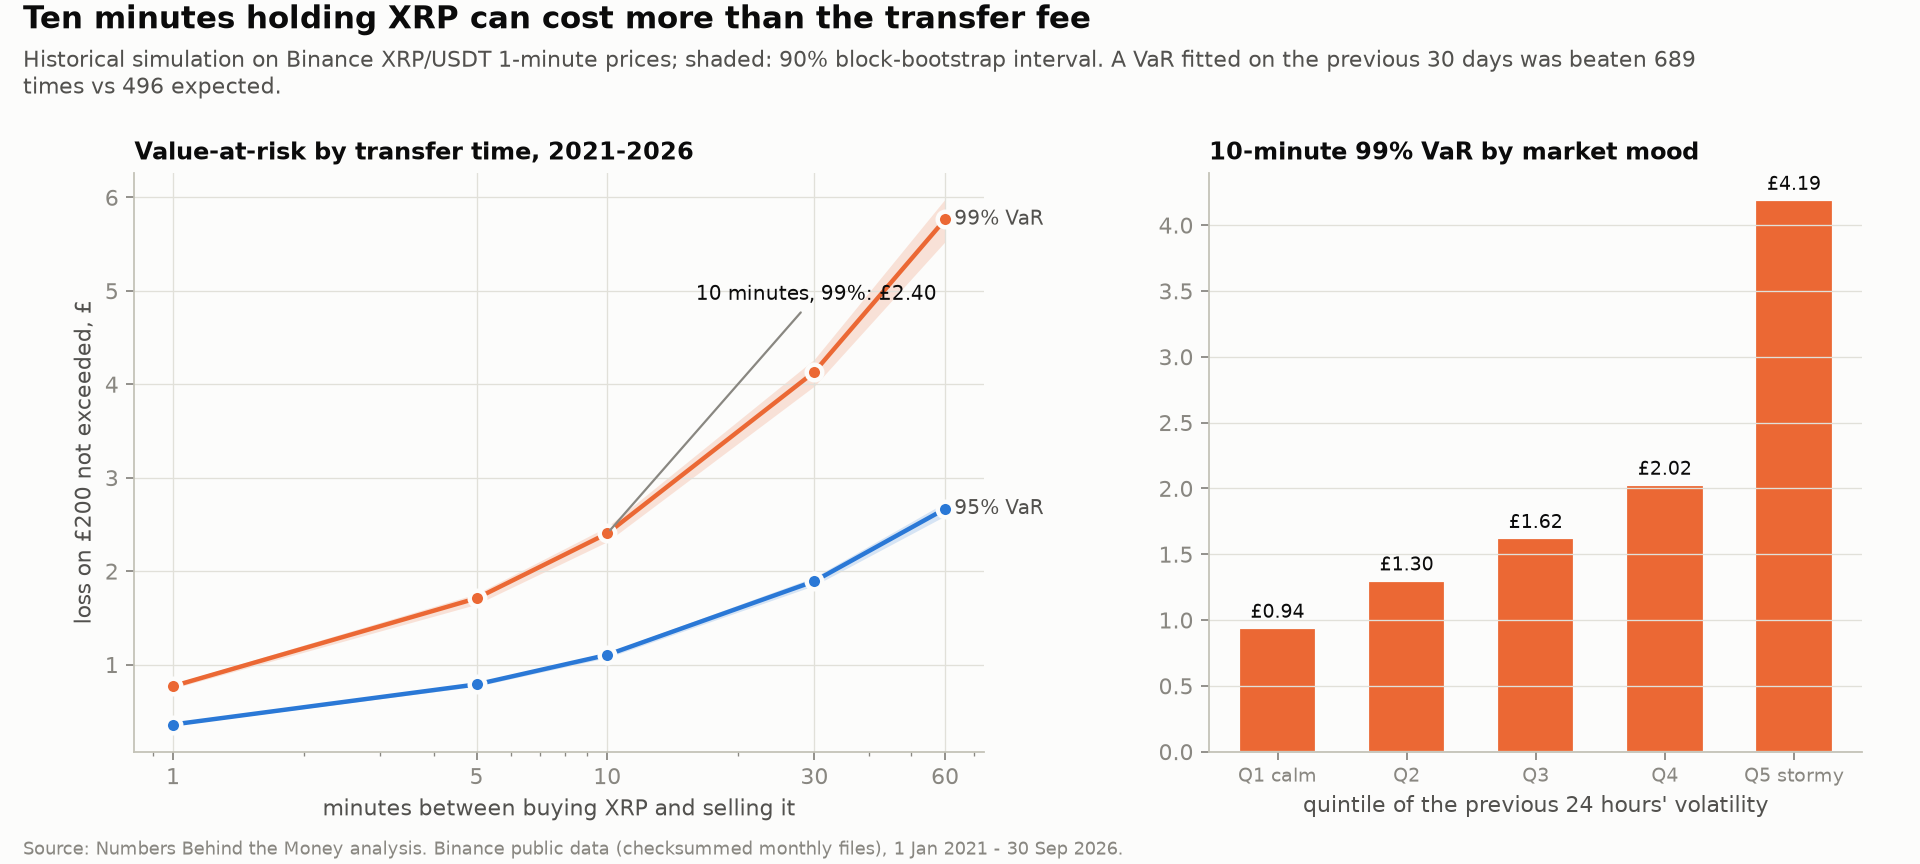

,horizon_min,level,n,var_pct,es_pct,var_lo_pct,var_hi_pct,var_gbp,es_gbp,sqrt_time_ratio
0,1,0.95,3021480,0.179,0.323,0.175,0.183,0.359,0.647,1.000
1,1,0.99,3021480,0.385,0.625,0.372,0.397,0.769,1.251,1.000
2,5,0.95,3021448,0.394,0.718,0.383,0.402,0.788,1.436,0.983
3,5,0.99,3021448,0.854,1.401,0.822,0.879,1.709,2.803,0.994
4,10,0.95,3021408,0.552,1.008,0.537,0.564,1.104,2.015,0.973
5,10,0.99,3021408,1.202,1.964,1.157,1.237,2.403,3.929,0.988
6,30,0.95,3021248,0.946,1.719,0.923,0.968,1.892,3.438,0.963
7,30,0.99,3021248,2.066,3.310,1.990,2.134,4.132,6.619,0.981
8,60,0.95,3021008,1.333,2.395,1.295,1.367,2.666,4.790,0.960
9,60,0.99,3021008,2.882,4.550,2.763,2.991,5.763,9.101,0.968


In [7]:
display(Image(figs['fig5_xrp_var']))
res['xrp_risk']['var'].round(3)

## 6. Stablecoin pegs

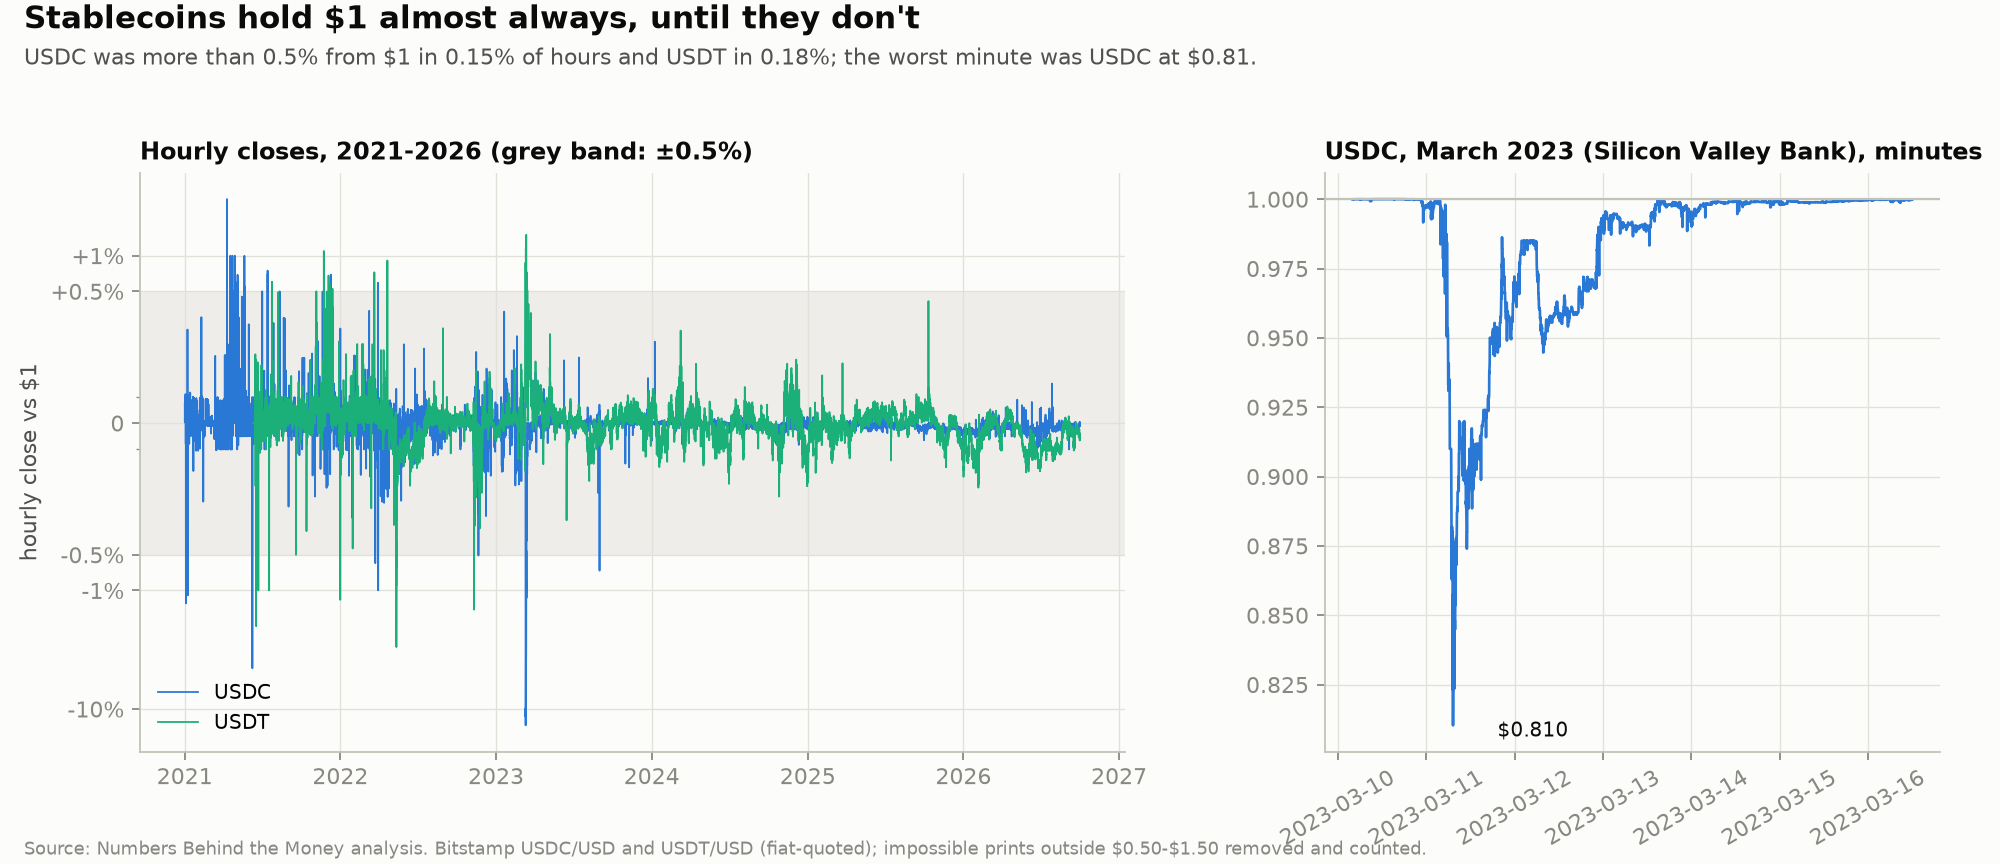

,pair,hours,first,last,worst_close,share_beyond_10bp,share_beyond_50bp,share_beyond_100bp
0,usdcusd,50376,2021-01-01 00:00:00+00:00,2026-09-30 23:00:00+00:00,0.86267,0.014312,0.001529,0.001012
1,usdtusd,46521,2021-06-10 12:00:00+00:00,2026-09-30 23:00:00+00:00,0.97000,0.114249,0.001827,0.000537


In [8]:
display(Image(figs['fig6_peg']))
res['peg']['bands']

## 7. Network fees vs what exchanges charge

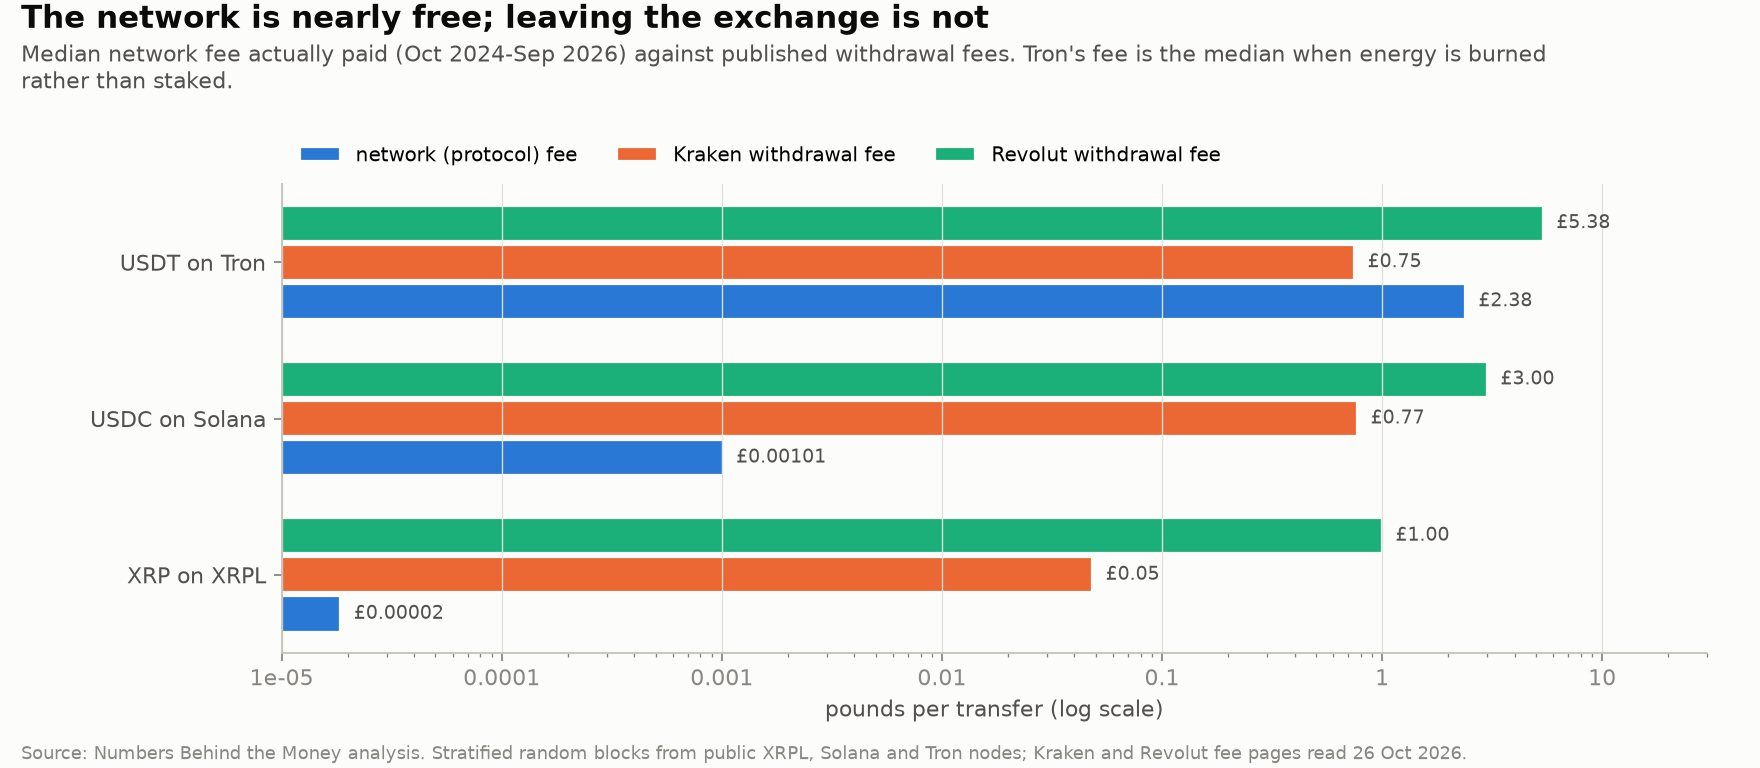

,network,p50,p90,p99,p99.9,max,n
0,XRPL: XRP payment,0.00002,0.00004,0.01739,0.42551,41.76452,17005.0
1,Solana: USDC transfer,0.00101,0.00573,0.08917,0.32245,0.33297,445.0
2,"Tron: USDT transfer, all",0.00000,1.68248,5.16617,6.98282,7.39109,38094.0
3,"Tron: USDT transfer, energy burned",2.38117,4.17724,6.83661,7.23084,7.39109,6237.0


In [9]:
display(Image(figs['fig7_fees']))
res['fees']['tails'].round(5)

## 8. Breakeven: when do the newer rails pay off?

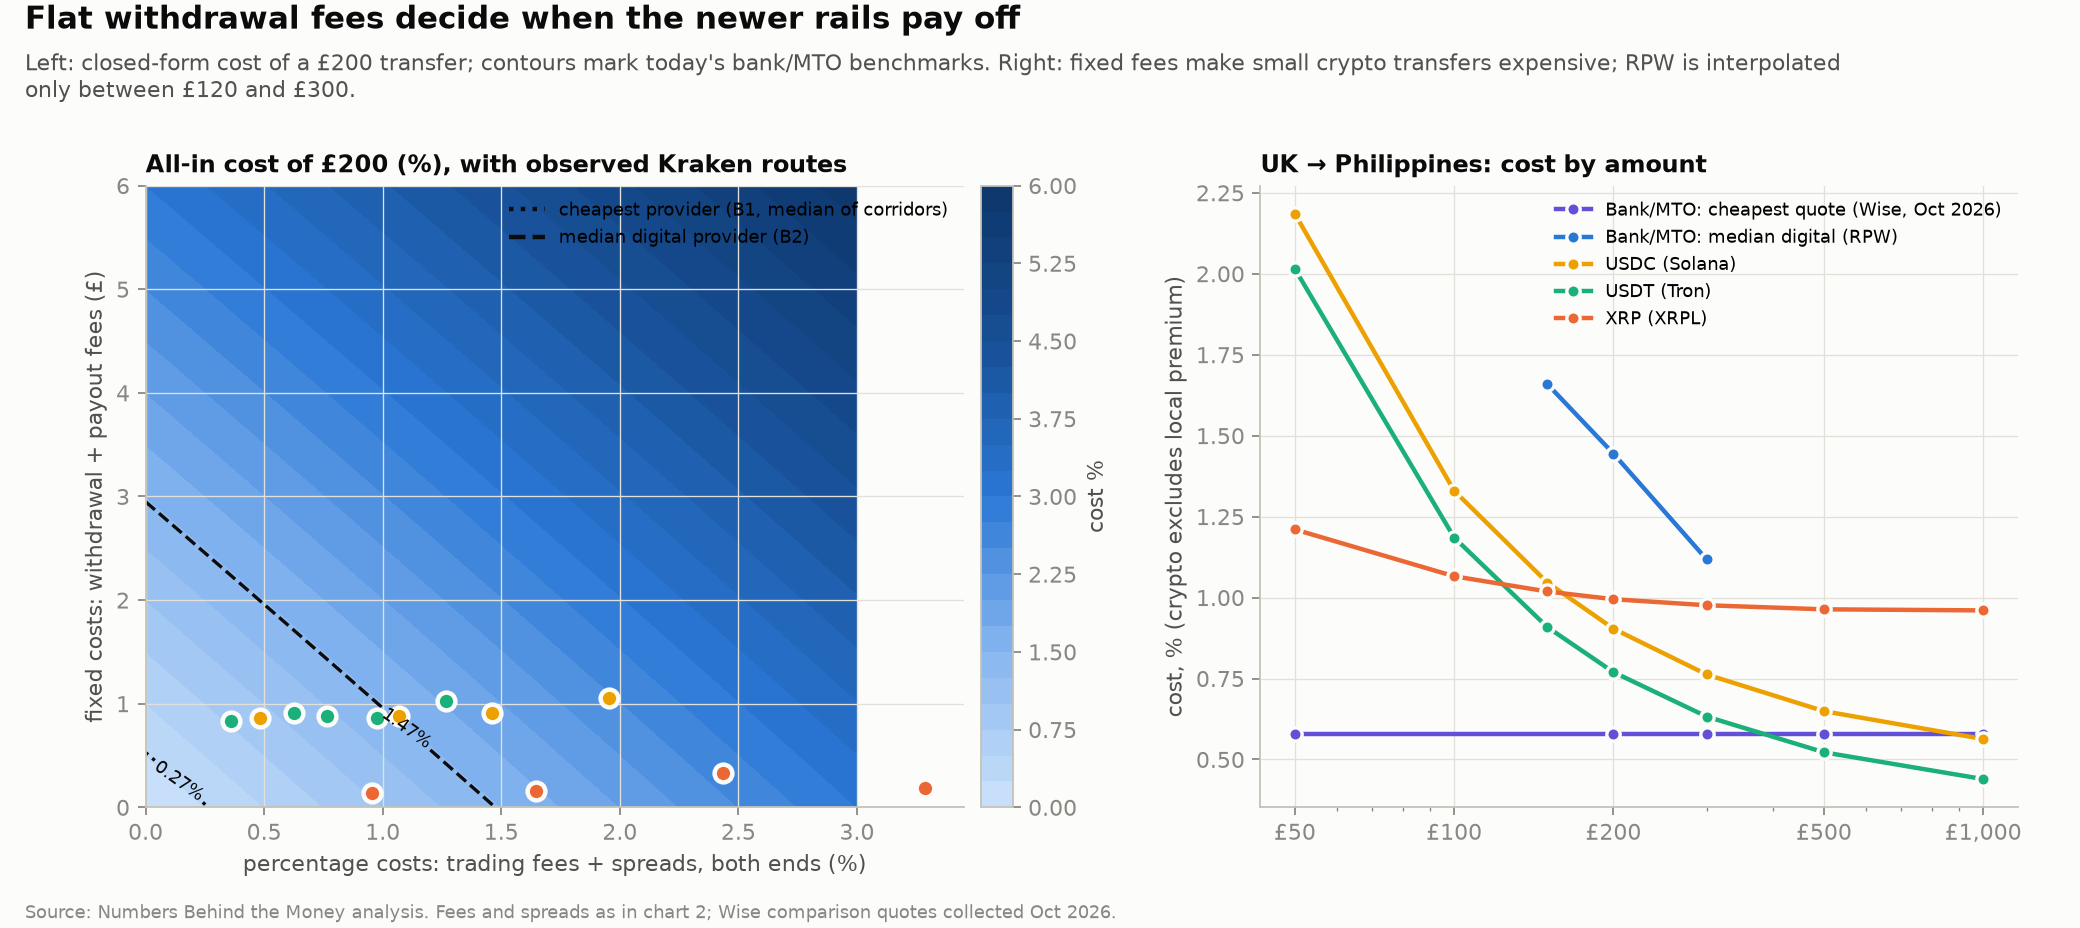

In [10]:
display(Image(figs['fig8_breakeven']))

## Summary table
`results/summary.csv` holds every headline number with its range, method and sample size.

In [11]:
res['summary'].head(30)

,section,corridor,rail,metric,estimate,low,high,unit,method,n
0,cost,GBR-IND,USDC (Solana),all-in cost (incl. local premium and tax),-3.788482,-4.203156,-3.305010,%,Monte Carlo over snapshots and fee ranges; route coinbase->coindcx,1000.0
1,cost,GBR-IND,USDC (Solana),cost excluding local premium and tax,1.403850,1.016657,1.903950,%,"as above, premium and tax legs removed",1000.0
2,cost,GBR-IND,USDC (Solana),share of cost in exchange rates (excl. premium),22.246085,NaN,NaN,%,"(spread + fx) / (fee + spread + fx), median draw",NaN
3,cost,GBR-IND,USDC (Solana),"P(beats cheapest digital provider, B1)",100.000000,NaN,NaN,%,,NaN
4,cost,GBR-IND,USDC (Solana),"P(beats median digital provider, B2)",100.000000,NaN,NaN,%,,NaN
5,cost,GBR-IND,USDT (Tron),all-in cost (incl. local premium and tax),-3.873655,-4.024925,-3.668051,%,Monte Carlo over snapshots and fee ranges; route kraken->coindcx,904.0
6,cost,GBR-IND,USDT (Tron),cost excluding local premium and tax,1.372045,1.098733,1.461150,%,"as above, premium and tax legs removed",904.0
7,cost,GBR-IND,USDT (Tron),share of cost in exchange rates (excl. premium),15.511772,NaN,NaN,%,"(spread + fx) / (fee + spread + fx), median draw",NaN
8,cost,GBR-IND,USDT (Tron),"P(beats cheapest digital provider, B1)",100.000000,NaN,NaN,%,,NaN
9,cost,GBR-IND,USDT (Tron),"P(beats median digital provider, B2)",100.000000,NaN,NaN,%,,NaN
